<a href="https://colab.research.google.com/github/erickvaldezsallagos/SISTEMAS-FINANCIEROS-Y-COMERCIALES/blob/main/PARCIAL2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EXAMEN SEGUNDO PARCIAL**
**SISTEMAS FINANCIEROS Y COMERCIALES**\
**CASTILLO DE LA TORRE ARES**\
**CRUZ PÉREZ REYNA LIZBETH**\
**VALDEZ SALLAGOS ERICK**

**Punto 2:**\
Elija cuatro empresas que coticen en bolsa de USA, escoja acciones con diferentes niveles de volatilidad,
justifique su respuesta

Se seleccionaron cuatro emisoras que cotizan en bolsas de Estados Unidos pertenecientes a distintos sectores y con perfiles de volatilidad diferenciados a lo largo de los cinco años históricos (18-nov-2019 al 15-nov-2024)


*   Consolidated Edison (ED): Empresa de servicios públicos (utilities / sector eléctrico) con comportamiento defensivo y la menor volatilidad diaria histórica de rendimientos logarítmicos, asociada a flujos regulados y demanda relativamente estable.
*   Alphabet (GOOG): Empresa tecnológica y de plataformas digitales de gran capitalización con volatilidad moderada-media, impulsada por crecimiento en publicidad digital, nube e inteligencia artificial, pero con mayor dispersión.


*   Netflix (NFLX): Empresa de entretenimiento y streaming con volatilidad elevada, sensible a crecimiento de suscriptores, competencia del sector y reportes trimestrales.
*   Boeing (BA): Empresa aeroespacial y de defensa con la mayor volatilidad diaria histórica, expuesta a ciclos de aviación comercial, cadenas de suministro y eventos operativos/regulatorios específicos.

**Contar con este rango de volatilidades permite contrastar activos defensivos frente a activos de mayor variabilidad tanto en el cálculo de riesgo como en la construcción de la cartera.**





Graficación de volatilidad de las acciones:

Descargando información histórica...


/tmp/ipykernel_6142/3656701971.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  4 of 4 completed


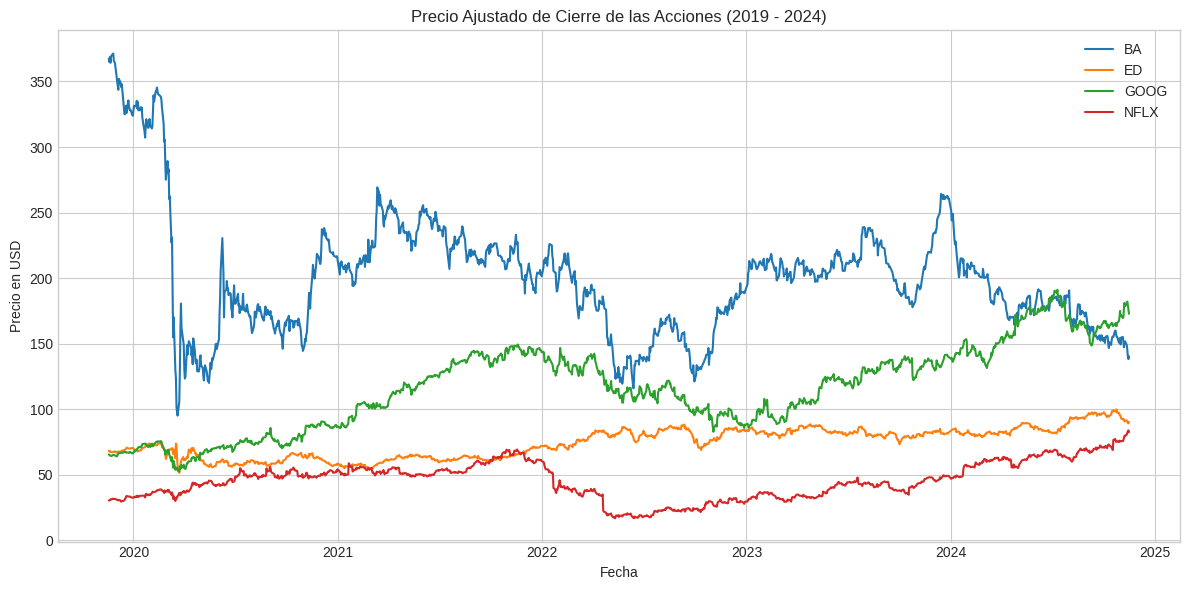

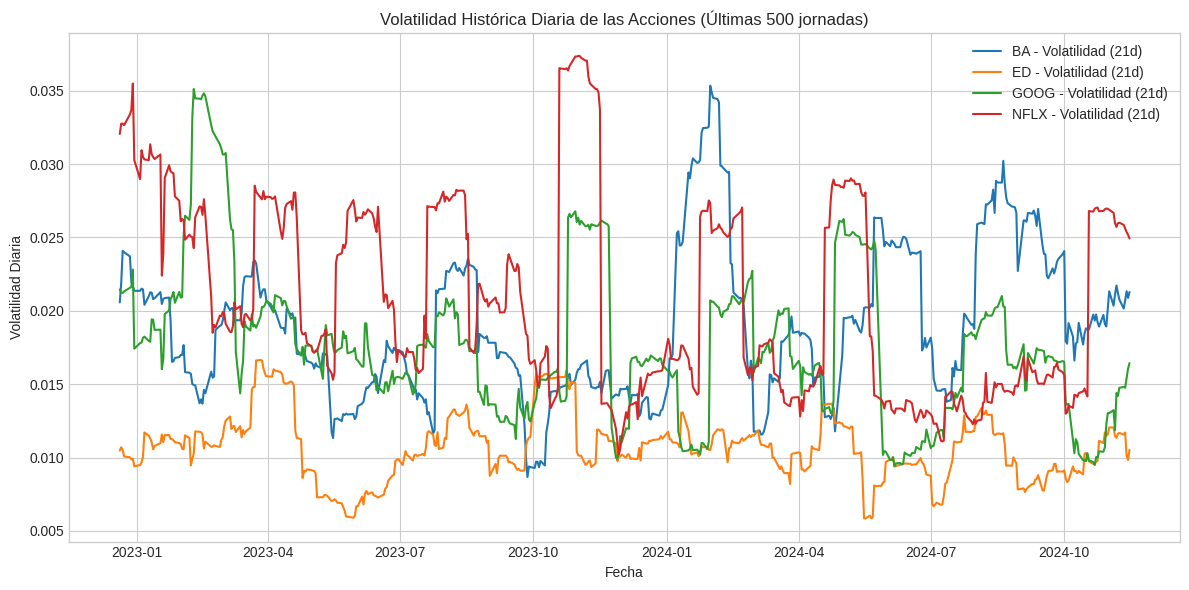

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Configuración de estilo
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Selección de Activos
tickers = ["ED", "GOOG", "BA", "NFLX"]
start_date = '2019-11-17'
end_date = '2024-11-17'

print("Descargando información histórica...")
data = yf.download(tickers, start=start_date, end=end_date)['Close']

# Limpieza preventiva: eliminamos columnas que estén completamente vacías (NaN) por fallos de descarga
data = data.dropna(how='all', axis=1)
disponible_tickers = list(data.columns)

# 2. GRÁFICA DE PRECIOS
plt.figure()
for ticker in disponible_tickers:
    plt.plot(data.index, data[ticker], label=ticker)
plt.title('Precio Ajustado de Cierre de las Acciones (2019 - 2024)')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD')
plt.legend()
plt.tight_layout()
plt.show()

# 3. Cálculo de Rendimientos y Volatilidad (Últimas 500 jornadas)
# Calculamos rendimientos y eliminamos filas que sean completamente NaN
returns = np.log(data / data.shift(1)).dropna(how='all')
returns_500 = returns.tail(500)

# Volatilidad paramétrica móvil (ventana de 21 días)
vol_parametrica = returns_500.rolling(window=21).std()

# 4. GRÁFICA DE VOLATILIDAD
plt.figure()
for ticker in disponible_tickers:
    # Graficamos solo si hay datos válidos de volatilidad para el ticker
    if ticker in vol_parametrica.columns and not vol_parametrica[ticker].isnull().all():
        plt.plot(vol_parametrica.index, vol_parametrica[ticker], label=f'{ticker} - Volatilidad (21d)')

plt.title('Volatilidad Histórica Diaria de las Acciones (Últimas 500 jornadas)')
plt.xlabel('Fecha')
plt.ylabel('Volatilidad Diaria')
plt.legend()
plt.tight_layout()
plt.show()

**Nota:**\
Usamos el excel de nuestros ejercicios resueltos, solo para consultar las bases de datos, ya que asi es más fácil trabajar con las datas historicas de los dos periodos ('Precios' y 'Precios2')

Adjuntaremos en otro colab, el código para obtener la data historica.

**PUNTO 3.**\
Consulte la información de dichas acciones para los últimos cinco años anteriores al día de HOY, calcule
su volatilidad histórica diaria de las últimas 500 jornadas, Grafique para hacer una comparación de su
comportamiento, consideré el método paramétrico, por simulación de Montecarlo y suavizamiento
exponencial.

**Código**

=== PUNTO 3A: RMSE POR VENTANA Y MEJOR VENTANA ===
           v20       v60      v120      v252
BA    0.857679  0.792172  0.752298  1.266538
ED    0.378326  0.321619  0.301648  0.522075
GOOG  0.727463  0.577652  0.589544  0.679023
NFLX  1.835421  1.478581  1.532763  1.647529
Mejor ventana por activo: {'BA': 120, 'ED': 120, 'GOOG': 60, 'NFLX': 60} 



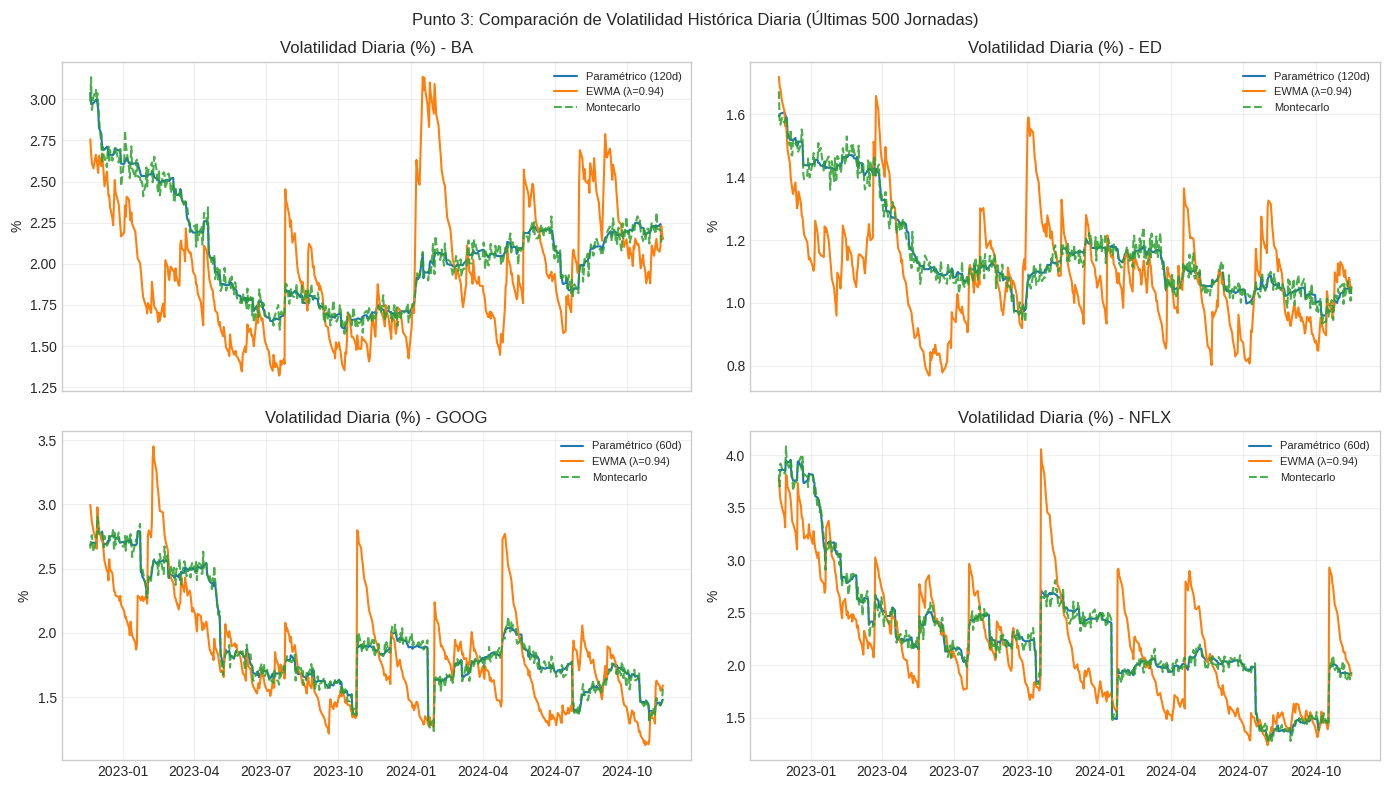

In [14]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# ------------------------------------------------------------------------------
# 0. CARGA DE DATOS HISTÓRICOS (SOLO 'Precios' Y 'Precios2')
# ------------------------------------------------------------------------------
FILENAME = "Parcial2_Excel_Solucion(examen).xlsx"

if not os.path.exists(FILENAME):
    try:
        from google.colab import files
        print("Sube el archivo 'Parcial2_Excel_Solucion(examen).xlsx':")
        uploaded = files.upload()
        if FILENAME not in uploaded and len(uploaded) > 0:
            FILENAME = list(uploaded.keys())[0]
    except ImportError:
        pass

assert os.path.exists(FILENAME), f"No se encontró '{FILENAME}'. Súbelo a Colab o colócalo aquí."

# Leemos exclusivamente las tablas de precios históricos
precios = pd.read_excel(FILENAME, sheet_name="Precios")    # 5 años: 18-nov-2019 a 15-nov-2024
precios2 = pd.read_excel(FILENAME, sheet_name="Precios2")  # 2 años posteriores: 18-nov-2024 a 16-nov-2026

precios["Date"] = pd.to_datetime(precios["Date"])
precios2["Date"] = pd.to_datetime(precios2["Date"])
precios = precios.sort_values("Date").reset_index(drop=True)
precios2 = precios2.sort_values("Date").reset_index(drop=True)


# ------------------------------------------------------------------------------
# PUNTO 3: Rendimientos logarítmicos (%) y volatilidad diaria (500 jornadas)
# Métodos: (1) Paramétrico (ventanas + RMSE), (2) EWMA, (3) Montecarlo
# ------------------------------------------------------------------------------
rend = pd.DataFrame({"Date": precios["Date"]})
for col in ACTIVOS + [BENCHMARK]:
    rend[col] = np.log(precios[col] / precios[col].shift(1)) * 100.0
rend["Portafolio"] = (rend[ACTIVOS].values * PESOS).sum(axis=1)

VENTANAS = [20, 60, 120, 252]
vol_param_ventanas = {}
rmse_resumen = {}
mejor_ventana = {}


idx_eval_rmse = np.arange(253, min(1239, len(rend)))

for col in ACTIVOS:
    s = rend[col]
    v_dict = {f"v{w}": s.rolling(w).std(ddof=1) for w in VENTANAS}
    df_v = pd.DataFrame(v_dict)
    # Volatilidad realizada en t = desviación de los 20 días posteriores (v20 deasplazada -20)
    realized = df_v["v20"].shift(-20)

    rmses = {}
    for w in VENTANAS:
        v_sub = df_v[f"v{w}"].iloc[idx_eval_rmse]
        r_sub = realized.iloc[idx_eval_rmse]
        mask = v_sub.notna() & r_sub.notna()
        rmses[f"v{w}"] = float(np.sqrt(np.mean((v_sub[mask] - r_sub[mask]) ** 2)))

    vol_param_ventanas[col] = df_v
    rmse_resumen[col] = rmses
    best_key = min(rmses, key=rmses.get)
    mejor_ventana[col] = int(best_key[1:])

print("=== PUNTO 3A: RMSE POR VENTANA Y MEJOR VENTANA ===")
print(pd.DataFrame(rmse_resumen).T)
print("Mejor ventana por activo:", mejor_ventana, "\n")

# EWMA diario (%)
vol_ewma = pd.DataFrame({"Date": rend["Date"]})
for col in ACTIVOS:
    r2 = rend[col] ** 2
    var_arr = np.full(len(rend), np.nan)
    fv = r2.first_valid_index()
    if fv is not None:
        var_arr[fv] = r2.iloc[fv]
        for t in range(fv + 1, len(rend)):
            if pd.notna(r2.iloc[t]):
                var_arr[t] = ALPHA_EWMA * r2.iloc[t] + LAMBDA_EWMA * var_arr[t - 1]
    vol_ewma[f"{col}_var"] = var_arr
    vol_ewma[f"{col}_vol"] = np.sqrt(var_arr)

# Simulación de Montecarlo (1,000 trayectorias diarias por jornada)
rng = np.random.default_rng(seed=42)
N_SIM = 1000
vol_mc = pd.DataFrame({"Date": rend["Date"]})
for col in ACTIVOS:
    w_opt = mejor_ventana[col]
    mu_m = rend[col].rolling(w_opt).mean()
    sd_m = rend[col].rolling(w_opt).std(ddof=1)
    mc_arr = np.full(len(rend), np.nan)
    valid_idx = np.where(mu_m.notna() & sd_m.notna())[0]
    if len(valid_idx) > 0:
        m_v = mu_m.iloc[valid_idx].values[:, None]
        s_v = sd_m.iloc[valid_idx].values[:, None]
        sims = m_v + s_v * rng.standard_normal((len(valid_idx), N_SIM))
        mc_arr[valid_idx] = np.std(sims, axis=1, ddof=1)
    vol_mc[col] = mc_arr

# Últimas 500 jornadas históricas
idx_500 = rend.index[-500:]
fechas_500 = rend.loc[idx_500, "Date"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, col in zip(axes.flat, ACTIVOS):
    w_opt = mejor_ventana[col]
    ax.plot(fechas_500, vol_param_ventanas[col][f"v{w_opt}"].loc[idx_500], label=f"Paramétrico ({w_opt}d)")
    ax.plot(fechas_500, vol_ewma[f"{col}_vol"].loc[idx_500], label="EWMA (λ=0.94)")
    ax.plot(fechas_500, vol_mc[col].loc[idx_500], label="Montecarlo", linestyle="--", alpha=0.85)
    ax.set_title(f"Volatilidad Diaria (%) - {col}")
    ax.set_ylabel("%")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.suptitle("Punto 3: Comparación de Volatilidad Histórica Diaria (Últimas 500 Jornadas)")
plt.tight_layout()
plt.show()

**PUNTO 4:**\
Construya un portafolio asignando pesos diferentes a estas acciones, argumente la diversificación con
base en la volatilidad de los instrumentos individuales y a su perfil de riesgo propio

**JUSTIFICACIÓN:**\
El portafolio se construyó asignando pesos diferenciados\
ED (35%), GOOG (30%), BA (20%) y NFLX (15%), sumando 100%, con base en un perfil de riesgo moderado y en la volatilidad relativa de cada activo.

Se otorgó el mayor peso a ED (35%) para anclar la estabilidad del portafolio y amortiguar caídas en episodios de estrés de mercado, acompañado de GOOG (30%) para capturar crecimiento estructural de largo plazo sin concentrar exceso de riesgo en las acciones más volátiles. A BA (20%) y NFLX (15%) se les asignaron participaciones menores para mantener potencial de retorno sin que su alta volatilidad individual domine por completo la varianza total. Al combinar activos de distintos sectores y correlaciones menores a uno, se logra diversificación, reduciendo el riesgo específico de cada empresa y obteniendo una beta de portafolio moderada.

**PUNTO 5:**\
Distribuya un millón de dólares en este portafolio (sin considerar comisiones ni impuestos)

**Código:**

In [15]:

FECHA_HOY_1 = pd.Timestamp("2024-11-17")  # Punto 1: corte inicial
FECHA_HOY_2 = pd.Timestamp("2026-11-17")  # Punto 14: corte final de evaluación

ACTIVOS = ["BA", "ED", "GOOG", "NFLX"]
BENCHMARK = "S&P500"
PESOS = np.array([0.20, 0.35, 0.30, 0.15])  # Suma = 1.00
assert np.isclose(PESOS.sum(), 1.0), "Los pesos deben sumar 1.0"

CAPITAL_INICIAL = 1_000_000.0
NIVEL_CONFIANZA = 0.95
Z_SCORE = float(norm.ppf(NIVEL_CONFIANZA))  # ~1.6448536269514715
HORIZONTE_VAR_DIAS = 1
LAMBDA_EWMA = 0.94
ALPHA_EWMA = 1.0 - LAMBDA_EWMA
DIAS_ANUALES = 252
ANIOS_PROY = 2
IRX_ANUAL_PCT = 4.5  # Tasa libre de riesgo ^IRX (%) al cierre del 15-nov-2024
RF_ANUAL_PCT = np.log(1.0 + IRX_ANUAL_PCT / 100.0) * 100.0

precios_ini = precios[ACTIVOS].iloc[-1].values.astype(float)
capital_asignado = PESOS * CAPITAL_INICIAL
titulos_fracc = capital_asignado / precios_ini
titulos_enteros = np.floor(titulos_fracc)
inversion_entera = titulos_enteros * precios_ini
remanente = capital_asignado - inversion_entera

df_capital = pd.DataFrame({
    "Activo": ACTIVOS,
    "Peso": PESOS,
    "Capital_Asignado ($)": capital_asignado,
    "Precio_15Nov2024 ($)": precios_ini,
    "Titulos_Fracc": titulos_fracc,
    "Titulos_Enteros": titulos_enteros,
    "Inv_Entera ($)": inversion_entera,
    "Remanente ($)": remanente,
})
print("=== PUNTOS 4 y 5: DISTRIBUCIÓN INICIAL DEL CAPITAL ($1,000,000) ===")
print(df_capital.to_string(index=False))
print(f"Títulos fraccionarios totales: {titulos_fracc.sum():.6f} | Enteros: {int(titulos_enteros.sum())}")
print(f"Inversión efectiva entera: ${inversion_entera.sum():,.2f} | Remanente: ${remanente.sum():,.2f}\n")

=== PUNTOS 4 y 5: DISTRIBUCIÓN INICIAL DEL CAPITAL ($1,000,000) ===
Activo  Peso  Capital_Asignado ($)  Precio_15Nov2024 ($)  Titulos_Fracc  Titulos_Enteros  Inv_Entera ($)  Remanente ($)
    BA  0.20              200000.0            140.190002    1426.635256           1426.0   199910.943481      89.056519
    ED  0.35              350000.0             90.981651    3846.929518           3846.0   349915.430923      84.569077
  GOOG  0.30              300000.0            172.681458    1737.302918           1737.0   299947.691711      52.308289
  NFLX  0.15              150000.0             82.396004    1820.476640           1820.0   149960.726776      39.273224
Títulos fraccionarios totales: 8831.344331 | Enteros: 8829
Inversión efectiva entera: $999,734.79 | Remanente: $265.21



**PUNTO 6:**\
Seleccione la serie histórica de volatilidades de entre las que generó en el punto 3, de acuerdo  a su perfil
de riesgo, calcule el Valor en Riesgo diario de las últimas 500 jornadas de cada uno de los activos
individuales, grafique comparando los activos seleccionados

**Justificación Selección de la serie histórica de volatilidad para el VaR individual**\
Para calcular el Valor en Riesgo (VaR) diario de las últimas 500 jornadas de cada activo individual, se seleccionó la serie de volatilidad dinámica EWMA ($\lambda = 0.94$) (en coherencia con un enfoque de monitoreo de riesgo prudente y sensible a cambios recientes del mercado).A diferencia de una media móvil simple de ventana fija que pondera por igual observaciones antiguas, el suavizamiento exponencial EWMA da mayor peso a las innovaciones cuadráticas más recientes (rend²), permitiendo que el VaR se ajuste con mayor rapidez cuando aumenta o disminuye la volatilidad del mercado. Esto resulta alineado con un perfil de riesgo que busca reflejar de forma oportuna las condiciones vigentes de riesgo sin depender de ventanas históricas largas que reaccionan con retraso.

**PUNTO 7:**\
Calcule el Valor en Riesgo diario de los últimos dos años del portafolio que decidió conformar, grafique.

=== PUNTOS 6 y 7: VaR DIARIO AL 15-NOV-2024 (USD) ===
  BA  : VaR Abs = $7,070.99 | VaR Rel = $7,386.82
  ED  : VaR Abs = $6,043.74 | VaR Rel = $5,908.08
  GOOG: VaR Abs = $7,853.78 | VaR Rel = $7,561.60
  NFLX: VaR Abs = $4,693.75 | VaR Rel = $4,349.29
  Port: VaR Abs = $12,601.06 | VaR Rel = $12,144.60



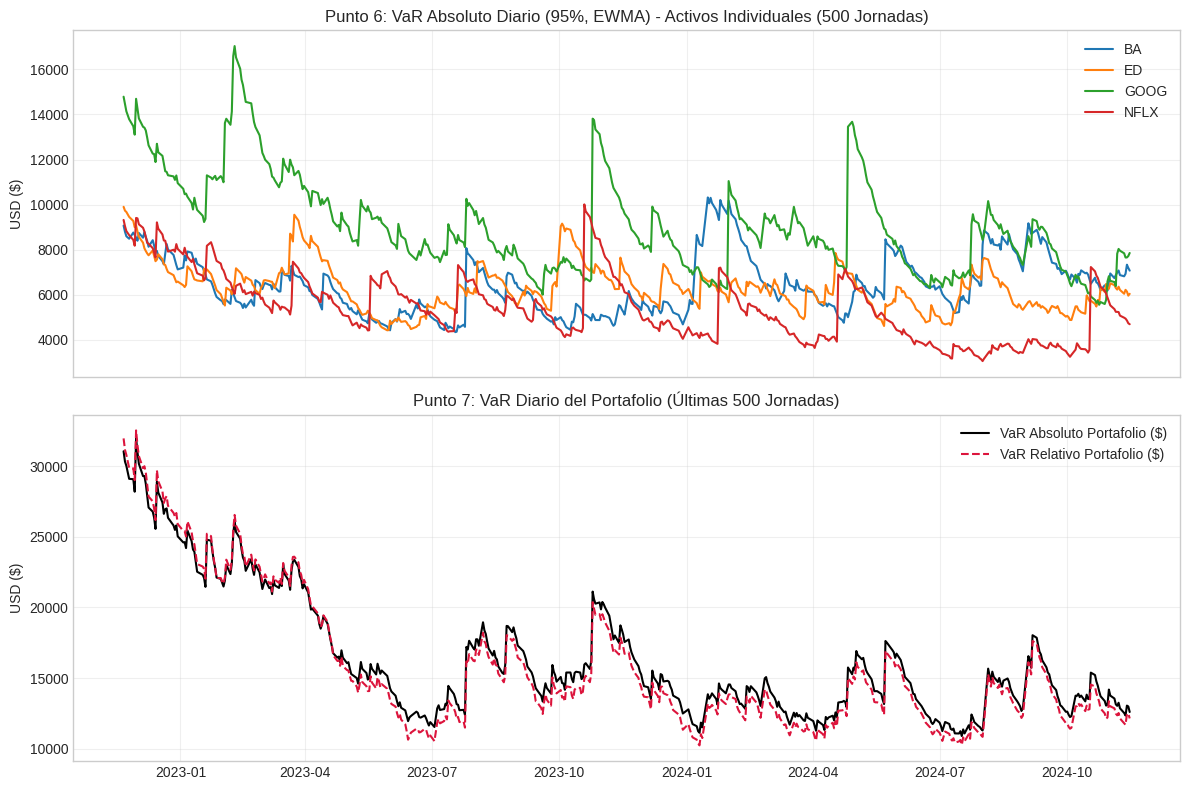

In [16]:
# ------------------------------------------------------------------------------
# PUNTOS 6 y 7: VaR diario (últimas 500 jornadas) con volatilidad EWMA (95%)
# ------------------------------------------------------------------------------
var_abs_activos = pd.DataFrame({"Date": fechas_500})
var_rel_activos = pd.DataFrame({"Date": fechas_500})

for i, col in enumerate(ACTIVOS):
    vol_d = vol_ewma[f"{col}_vol"].loc[idx_500] / 100.0
    mu_252 = (rend[col].rolling(252).mean() / 100.0).loc[idx_500]
    var_abs_activos[col] = Z_SCORE * PESOS[i] * CAPITAL_INICIAL * vol_d * HORIZONTE_VAR_DIAS
    var_rel_activos[col] = PESOS[i] * CAPITAL_INICIAL * (Z_SCORE * vol_d - mu_252) * HORIZONTE_VAR_DIAS

port_r2 = rend["Portafolio"] ** 2
port_var = np.full(len(rend), np.nan)
fp = port_r2.first_valid_index()
port_var[fp] = port_r2.iloc[fp]
for t in range(fp + 1, len(rend)):
    if pd.notna(port_r2.iloc[t]):
        port_var[t] = ALPHA_EWMA * port_r2.iloc[t] + LAMBDA_EWMA * port_var[t - 1]
port_vol = np.sqrt(port_var)

vol_p_500 = port_vol[idx_500] / 100.0
mu_p_252 = (rend["Portafolio"].rolling(252).mean() / 100.0).loc[idx_500]
var_abs_port = Z_SCORE * CAPITAL_INICIAL * vol_p_500 * HORIZONTE_VAR_DIAS
var_rel_port = CAPITAL_INICIAL * (Z_SCORE * vol_p_500 - mu_p_252) * HORIZONTE_VAR_DIAS

print("=== PUNTOS 6 y 7: VaR DIARIO AL 15-NOV-2024 (USD) ===")
for col in ACTIVOS:
    print(f"  {col:4s}: VaR Abs = ${var_abs_activos[col].iloc[-1]:,.2f} | VaR Rel = ${var_rel_activos[col].iloc[-1]:,.2f}")
print(f"  Port: VaR Abs = ${var_abs_port[-1]:,.2f} | VaR Rel = ${var_rel_port.iloc[-1]:,.2f}\n")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for col in ACTIVOS:
    ax1.plot(fechas_500, var_abs_activos[col], label=col)
ax1.set_title("Punto 6: VaR Absoluto Diario (95%, EWMA) - Activos Individuales (500 Jornadas)")
ax1.set_ylabel("USD ($)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(fechas_500, var_abs_port, color="black", label="VaR Absoluto Portafolio ($)")
ax2.plot(fechas_500, var_rel_port, color="crimson", linestyle="--", label="VaR Relativo Portafolio ($)")
ax2.set_title("Punto 7: VaR Diario del Portafolio (Últimas 500 Jornadas)")
ax2.set_ylabel("USD ($)")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Punto 8:**\
Calcule las betas de los activos individuales

**Punto 9:**\
Calcule la beta del portafolio

**Punto 10:**\
Establezca criterios para aplicar SMA, WMA o EMA en un análisis posterior al día de HOY, durante los
siguientes 2 años, de estas tres acciones (pueden ser diferentes por acción), justifique su respuesta, grafique

**Criterios y justificación para aplicar SMA, WMA o EMA**\
Para el seguimiento de tendencia durante los dos años posteriores al corte inicial (18-nov-2024 al 16-nov-2026), se eligieron distintos tipos y longitudes de medias móviles según la dinámica de cada acción:

ED con EMA(20): Al ser un activo de movimiento más pausado y defensivo, una media exponencial corta de 20 jornadas (EMA(20)) otorga mayor ponderación a los precios recientes y permite detectar cambios de tendencia o consolidaciones de corto plazo con oportunidad.

GOOG con EMA(50) y SMA(100): Combinar una media exponencial de mediano plazo (EMA(50), más sensible a cambios recientes) con una media simple de largo plazo (SMA(100), donde cada jornada pesa igual) permite contrastar el impulso intermedio frente a la tendencia estructural de 100 días.

NFLX con WMA(100) (y BA con SMA(100)): En NFLX, la media móvil ponderada linealmente de 100 días (WMA(100), con pesos crecientes 1 a 100 hacia los datos más recientes) filtra el ruido diario de una acción volátil pero prioriza los precios más cercanos dentro de una ventana amplia de 100 jornadas; en BA, la SMA(100) ofrece una referencia suavizada de tendencia de 100 días.

**Punto 11:**\
Establezca criterios para implementar MACD y/o RSI en el portafolio (pueden ser diferentes por acción),
justifique su respuesta.

**Criterios y justificación para implementar MACD y/o RSI en el portafolio**\
Se implementaron MACD(19, 39, 9) y RSI(14) como señales complementarias de momentum y condición de sobrecompra/sobreventa para BA y NFLX (dos de los activos con mayor volatilidad/dinámica del portafolio):

MACD(19, 39, 9): Mide la diferencia entre una media exponencial rápida (19) y una lenta (39), comparada contra su línea de señal (9). Un cruce del MACD por encima de la señal indica aceleración alcista, mientras que un cruce por debajo de la señal indica pérdida de impulso o giro bajista.

Filtro con RSI(14): El RSI(14) actúa como filtro de confirmación para evitar comprar en zonas ya sobreextendidas o vender en condiciones extremas:

En BA, se usan umbrales de 20 (sobreventa) y 80 (sobrecompra), acordes con su mayor amplitud de fluctuaciones: se exige RSI < 80 en compras alcistas de MACD y RSI > 20 en ventas bajistas de MACD.

En NFLX, se emplean umbrales clásicos de 30 y 70 (RSI < 70 para compras en cruce alcista y RSI > 30 para ventas en cruce bajista), buscando filtrar entradas tardías tras impulsos fuertes y salidas en extremos.

**Punto 14:**\
 Suponga que el día de HOY nuevamente es el 17 de noviembre de 2026

**Punto 15:**\
Identifique todos los momentos donde, considerando los criterios que usted estableció en los puntos
anteriores,  debieron de haberse ejecutado ordenes de compra o venta en el periodo del 17 de
noviembre de 2024 al 17 de noviembre de 2026. Realice una bitácora indicando fecha y movimientos
específicos.

**Observación:** Estos ejercicios se relacion, ya que necesitamos sacar otra data historica de años más recientes

**DATA HISTORICA**

**Código (de los ejercicios 10, 11, 14 y 15):**

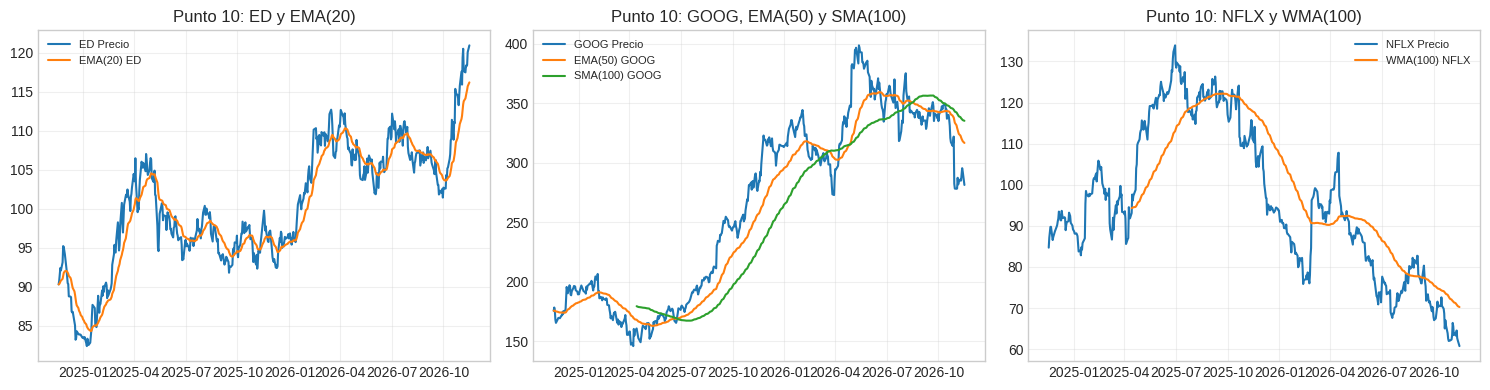

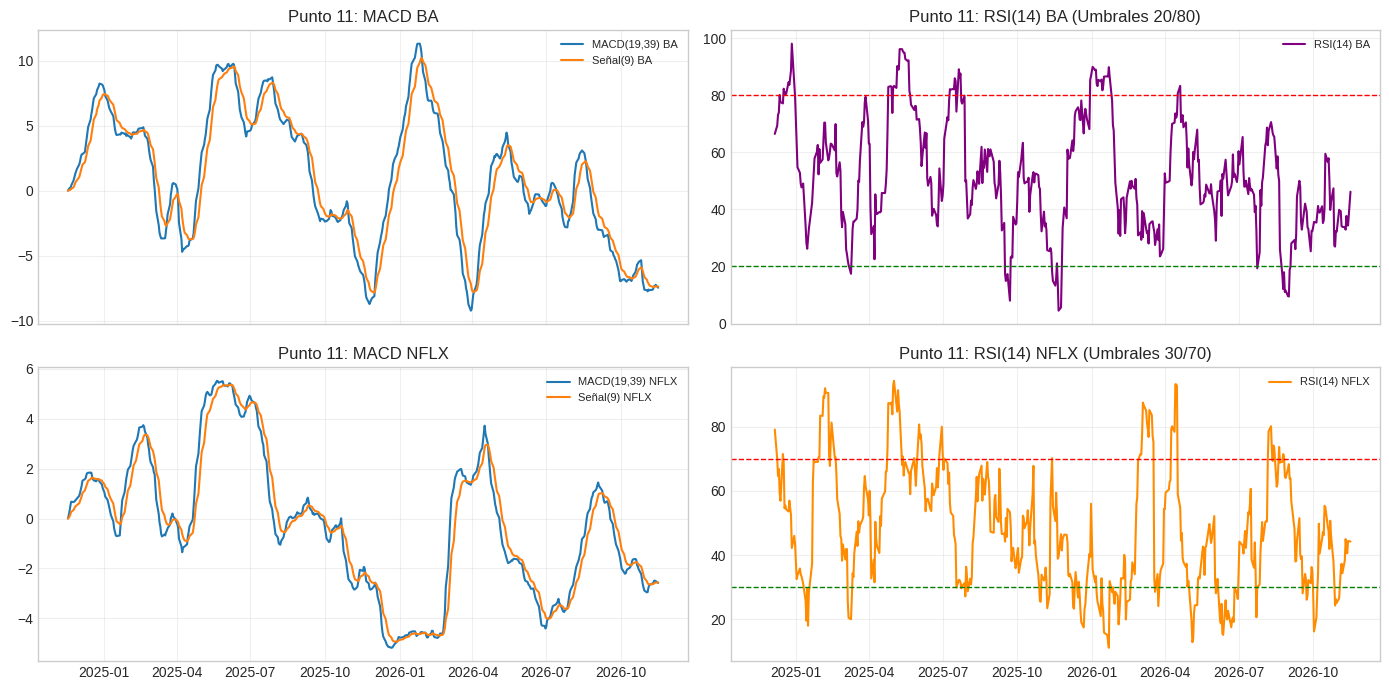

=== PUNTO 15: BITÁCORA DE ÓRDENES (Total movimientos: 126) ===
     Fecha Activo           Tipo                                Regla     Precio     Titulos         Monto  Efectivo_Post
2024-11-15     BA Compra Inicial             Asignación inicial (20%) 140.190002 1426.635256 200000.000000       0.000000
2024-11-15     ED Compra Inicial             Asignación inicial (35%)  90.981651 3846.929518 350000.000000       0.000000
2024-11-15   GOOG Compra Inicial             Asignación inicial (30%) 172.681458 1737.302918 300000.000000       0.000000
2024-11-15   NFLX Compra Inicial             Asignación inicial (15%)  82.396004 1820.476640 150000.000000       0.000000
2024-12-03     ED          Venta           Precio cruza abajo EMA(20)  91.324692 3846.929518 351319.652496  351319.652496
2024-12-19   NFLX          Venta MACD(19,39,9) bajista + RSI(55.5)>30  90.204002 1820.476640 164214.279160  164214.279160
2025-01-03     BA          Venta MACD(19,39,9) bajista + RSI(54.8)>20 169.899994 14

In [17]:
p2 = precios2.copy()

# Medias móviles (Punto 10)
p2["EMA20_ED"] = p2["ED"].ewm(span=20, adjust=False).mean()
p2["SMA100_BA"] = p2["BA"].rolling(100).mean()
p2["EMA50_GOOG"] = p2["GOOG"].ewm(span=50, adjust=False).mean()
p2["SMA100_GOOG"] = p2["GOOG"].rolling(100).mean()
pesos_wma = np.arange(1, 101, dtype=float)
p2["WMA100_NFLX"] = p2["NFLX"].rolling(100).apply(lambda x: np.dot(x, pesos_wma) / pesos_wma.sum(), raw=True)

# MACD(19,39,9) y RSI(14) (Punto 11)
def calc_macd(series, fast=19, slow=39, signal=9):
    ema_f = series.ewm(span=fast, adjust=False).mean()
    ema_s = series.ewm(span=slow, adjust=False).mean()
    macd_l = ema_f - ema_s
    sig_l = macd_l.ewm(span=signal, adjust=False).mean()
    return macd_l, sig_l, macd_l - sig_l

p2["MACD_BA"], p2["SIG_BA"], p2["HIST_BA"] = calc_macd(p2["BA"], 19, 39, 9)
p2["MACD_NFLX"], p2["SIG_NFLX"], p2["HIST_NFLX"] = calc_macd(p2["NFLX"], 19, 39, 9)

def calc_rsi_14(series):
    ret = series.pct_change()
    gain = ret.clip(lower=0.0).fillna(0.0)
    loss = (-ret).clip(lower=0.0).fillna(0.0)
    sg = gain.rolling(14).sum()
    sl = loss.rolling(14).sum()
    rsi = np.where(sg.isna() | sl.isna(), np.nan,
                   np.where(sl == 0, 100.0, 100.0 - 100.0 / (1.0 + sg / sl)))
    return pd.Series(rsi, index=series.index)

p2["RSI_BA"] = calc_rsi_14(p2["BA"])
p2["RSI_NFLX"] = calc_rsi_14(p2["NFLX"])

# Gráficas Punto 10
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(p2["Date"], p2["ED"], label="ED Precio")
axes[0].plot(p2["Date"], p2["EMA20_ED"], label="EMA(20) ED")
axes[0].set_title("Punto 10: ED y EMA(20)")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].plot(p2["Date"], p2["GOOG"], label="GOOG Precio")
axes[1].plot(p2["Date"], p2["EMA50_GOOG"], label="EMA(50) GOOG")
axes[1].plot(p2["Date"], p2["SMA100_GOOG"], label="SMA(100) GOOG")
axes[1].set_title("Punto 10: GOOG, EMA(50) y SMA(100)")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

axes[2].plot(p2["Date"], p2["NFLX"], label="NFLX Precio")
axes[2].plot(p2["Date"], p2["WMA100_NFLX"], label="WMA(100) NFLX")
axes[2].set_title("Punto 10: NFLX y WMA(100)")
axes[2].legend(fontsize=8)
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gráficas Punto 11
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
axes[0, 0].plot(p2["Date"], p2["MACD_BA"], label="MACD(19,39) BA")
axes[0, 0].plot(p2["Date"], p2["SIG_BA"], label="Señal(9) BA")
axes[0, 0].set_title("Punto 11: MACD BA")
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(p2["Date"], p2["RSI_BA"], color="purple", label="RSI(14) BA")
axes[0, 1].axhline(80, color="red", linestyle="--", linewidth=1)
axes[0, 1].axhline(20, color="green", linestyle="--", linewidth=1)
axes[0, 1].set_title("Punto 11: RSI(14) BA (Umbrales 20/80)")
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(p2["Date"], p2["MACD_NFLX"], label="MACD(19,39) NFLX")
axes[1, 0].plot(p2["Date"], p2["SIG_NFLX"], label="Señal(9) NFLX")
axes[1, 0].set_title("Punto 11: MACD NFLX")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(p2["Date"], p2["RSI_NFLX"], color="darkorange", label="RSI(14) NFLX")
axes[1, 1].axhline(70, color="red", linestyle="--", linewidth=1)
axes[1, 1].axhline(30, color="green", linestyle="--", linewidth=1)
axes[1, 1].set_title("Punto 11: RSI(14) NFLX (Umbrales 30/70)")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Bitácora de órdenes (Punto 15 - corregido con cruce estricto y validación de NaN)
posiciones = {
    col: {"shares": float(titulos_fracc[i]), "cash": 0.0}
    for i, col in enumerate(ACTIVOS)
}
bitacora = []
for i, col in enumerate(ACTIVOS):
    bitacora.append({
        "Fecha": pd.Timestamp("2024-11-15"),
        "Activo": col,
        "Tipo": "Compra Inicial",
        "Regla": f"Asignación inicial ({int(PESOS[i]*100)}%)",
        "Precio": float(precios_ini[i]),
        "Titulos": float(titulos_fracc[i]),
        "Monto": float(capital_asignado[i]),
        "Efectivo_Post": 0.0,
    })

for idx in range(1, len(p2)):
    r_prev = p2.iloc[idx - 1]
    r_curr = p2.iloc[idx]
    fecha = r_curr["Date"]

    # ED: Cruce estricto con EMA(20)
    d_ed_prev = r_prev["ED"] - r_prev["EMA20_ED"]
    d_ed_curr = r_curr["ED"] - r_curr["EMA20_ED"]
    st_ed = posiciones["ED"]
    if pd.notna(d_ed_prev) and pd.notna(d_ed_curr):
        if d_ed_prev > 0 and d_ed_curr < 0 and st_ed["shares"] > 0:
            monto = st_ed["shares"] * r_curr["ED"]
            st_ed["cash"] += monto
            bitacora.append({
                "Fecha": fecha, "Activo": "ED", "Tipo": "Venta",
                "Regla": "Precio cruza abajo EMA(20)", "Precio": float(r_curr["ED"]),
                "Titulos": float(st_ed["shares"]), "Monto": float(monto),
                "Efectivo_Post": float(st_ed["cash"])
            })
            st_ed["shares"] = 0.0
        elif d_ed_prev < 0 and d_ed_curr > 0 and st_ed["cash"] > 0:
            monto = st_ed["cash"]
            sh_buy = monto / r_curr["ED"]
            st_ed["shares"] += sh_buy
            st_ed["cash"] = 0.0
            bitacora.append({
                "Fecha": fecha, "Activo": "ED", "Tipo": "Compra",
                "Regla": "Precio cruza arriba EMA(20)", "Precio": float(r_curr["ED"]),
                "Titulos": float(sh_buy), "Monto": float(monto),
                "Efectivo_Post": float(st_ed["cash"])
            })

    # BA y NFLX: Cruce estricto MACD(19,39,9) + filtro RSI(14)
    for col, rsi_c, m_c, s_c, low_th, high_th in [
        ("BA", "RSI_BA", "MACD_BA", "SIG_BA", 20.0, 80.0),
        ("NFLX", "RSI_NFLX", "MACD_NFLX", "SIG_NFLX", 30.0, 70.0),
    ]:
        dp = r_prev[m_c] - r_prev[s_c]
        dc = r_curr[m_c] - r_curr[s_c]
        rsi_v = r_curr[rsi_c]
        st = posiciones[col]
        if pd.notna(dp) and pd.notna(dc) and pd.notna(rsi_v):
            if dp > 0 and dc < 0 and rsi_v > low_th and st["shares"] > 0:
                monto = st["shares"] * r_curr[col]
                st["cash"] += monto
                bitacora.append({
                    "Fecha": fecha, "Activo": col, "Tipo": "Venta",
                    "Regla": f"MACD(19,39,9) bajista + RSI({rsi_v:.1f})>{low_th:.0f}",
                    "Precio": float(r_curr[col]), "Titulos": float(st["shares"]),
                    "Monto": float(monto), "Efectivo_Post": float(st["cash"])
                })
                st["shares"] = 0.0
            elif dp < 0 and dc > 0 and rsi_v < high_th and st["cash"] > 0:
                monto = st["cash"]
                sh_buy = monto / r_curr[col]
                st["shares"] += sh_buy
                st["cash"] = 0.0
                bitacora.append({
                    "Fecha": fecha, "Activo": col, "Tipo": "Compra",
                    "Regla": f"MACD(19,39,9) alcista + RSI({rsi_v:.1f})<{high_th:.0f}",
                    "Precio": float(r_curr[col]), "Titulos": float(sh_buy),
                    "Monto": float(monto), "Efectivo_Post": float(st["cash"])
                })

df_bitacora = pd.DataFrame(bitacora)
print(f"=== PUNTO 15: BITÁCORA DE ÓRDENES (Total movimientos: {len(df_bitacora)}) ===")
print(df_bitacora.to_string(index=False))
print()


**Punto 12**\
Proponga un método para hacer la proyección del mercado estadounidense con base en los datos del
periodo analizado.

**Método propuesto para proyectar el mercado estadounidense (S&P 500)**\
Para proyectar el índice S&P 500 a dos años (500 jornadas) a partir de los cinco años de datos históricos (18-nov-2019 al 15-nov-2024), se propone un Movimiento Geométrico Browniano (GBM) calibrado con los rendimientos logarítmicos diarios históricos del índice:Se estiman el rendimiento logarítmico diario promedio ($\mu_d \approx 0.000502$, equivalente a ~12.66% anualizado continuo con 252 días) y la volatilidad diaria histórica ($\sigma_d \approx 0.013465$, equivalente a 21.37% anualizada).Se justifica el GBM porque modela precios positivos de forma multiplicativa y continua, captura la deriva histórica ($\mu_d$) y la dispersión estocástica ($\sigma_d \sqrt{t}$), y permite obtener tanto la trayectoria central/mediana log-normal ($S_0 e^{\mu_d t}$) y el ajuste por lema de Itô ($S_0 e^{(\mu_d + \frac{1}{2}\sigma_d^2)t}$) como bandas de confianza al 95% a lo largo del horizonte proyectado.

**Punto 13:**\
Haciendo uso de CAPM, proyecte el rendimiento esperado de su portafolio considerando que no tiene
cambios en el periodo del 17 de noviembre de 2024 al 17 de noviembre de 2026.

**Punto 16:**\
Realice la comparación del rendimiento esperado calculado con CAPM y el rendimiento real que tuvo su
portafolio de acuerdo al inciso 15.

**Código (12, 13, 16):**

In [18]:
# ------------------------------------------------------------------------------
# PUNTOS 12, 13 y 16: Proyección S&P 500 (GBM), CAPM y Comparación Real
# ------------------------------------------------------------------------------
s0_sp500 = float(precios[BENCHMARK].iloc[-1])
mu_d_sp = float(rend[BENCHMARK].mean() / 100.0)
sigma_d_sp = float(rend[BENCHMARK].std(ddof=1) / 100.0)
rm_anual_pct = mu_d_sp * DIAS_ANUALES * 100.0

sp500_mediana_500d = s0_sp500 * np.exp(mu_d_sp * 500)
sp500_media_ito_500d = s0_sp500 * np.exp((mu_d_sp + 0.5 * sigma_d_sp ** 2) * 500)

erp_anual_pct = RF_ANUAL_PCT + betas["Portafolio"] * (rm_anual_pct - RF_ANUAL_PCT)
erp_2y_pct = erp_anual_pct * ANIOS_PROY
val_capm_2y = CAPITAL_INICIAL * np.exp(erp_2y_pct / 100.0)

precios_fin = p2[ACTIVOS].iloc[-1].values.astype(float)
val_buy_and_hold = float((titulos_fracc * precios_fin).sum())
val_activa = float(sum(posiciones[col]["cash"] + posiciones[col]["shares"] * p2[col].iloc[-1] for col in ACTIVOS))

resumen_final = pd.DataFrame({
    "Escenario": [
        "1. Esperado CAPM (2 años)",
        "2. Real Pasivo (Buy & Hold)",
        "3. Real Gestión Activa",
    ],
    "Capital_Inicial ($)": [CAPITAL_INICIAL] * 3,
    "Valor_Final ($)": [val_capm_2y, val_buy_and_hold, val_activa],
    "Ganancia_Neta ($)": [val_capm_2y - CAPITAL_INICIAL, val_buy_and_hold - CAPITAL_INICIAL, val_activa - CAPITAL_INICIAL],
    "Rend_Efectivo (%)": [
        (val_capm_2y / CAPITAL_INICIAL - 1) * 100,
        (val_buy_and_hold / CAPITAL_INICIAL - 1) * 100,
        (val_activa / CAPITAL_INICIAL - 1) * 100,
    ],
    "Rend_Continuo (%)": [
        erp_2y_pct,
        np.log(val_buy_and_hold / CAPITAL_INICIAL) * 100,
        np.log(val_activa / CAPITAL_INICIAL) * 100,
    ],
    "Dif_vs_CAPM ($)": [0.0, val_buy_and_hold - val_capm_2y, val_activa - val_capm_2y],
})

print("=== PUNTOS 12, 13 y 16: PROYECCIÓN S&P 500, CAPM Y COMPARACIÓN FINAL ===")
print(f"S&P 500 inicial: {s0_sp500:.2f} | Rm anual continuo: {rm_anual_pct:.6f}%")
print(f"S&P 500 día 500 (mediana log-normal): {sp500_mediana_500d:.2f} | (media Itô): {sp500_media_ito_500d:.2f}\n")
print(resumen_final.to_string(index=False))

=== PUNTOS 12, 13 y 16: PROYECCIÓN S&P 500, CAPM Y COMPARACIÓN FINAL ===
S&P 500 inicial: 5870.62 | Rm anual continuo: 12.659679%
S&P 500 día 500 (mediana log-normal): 7546.96 | (media Itô): 7896.89

                  Escenario  Capital_Inicial ($)  Valor_Final ($)  Ganancia_Neta ($)  Rend_Efectivo (%)  Rend_Continuo (%)  Dif_vs_CAPM ($)
  1. Esperado CAPM (2 años)            1000000.0     1.279685e+06      279685.041317          27.968504          24.661399         0.000000
2. Real Pasivo (Buy & Hold)            1000000.0     1.300308e+06      300308.226220          30.030823          26.260133     20623.184903
     3. Real Gestión Activa            1000000.0     1.248839e+06      248838.611089          24.883861          22.221401    -30846.430228


**Comparación del rendimiento esperado por CAPM frente al rendimiento real**\
Al contrastar el rendimiento esperado por el modelo CAPM (calibrado con la beta del portafolio, la tasa libre de riesgo y el rendimiento de mercado histórico) frente a los resultados reales observados durante los dos años posteriores al corte inicial, se identifican dinámicas distintas entre estrategias:

Portafolio Pasivo (Buy & Hold): Al mantener las posiciones iniciales sin cambios, logra capturar íntegramente las tendencias positivas de los activos con mejor desempeño  (como el avance acumulado de GOOG y ED), lo cual compensa el retroceso de NFLX y permite que el portafolio supere la proyección teórica del CAPM en este periodo.

Portafolio con Gestión Activa (Bitácora del Punto 15): Operar según los indicadores técnicos genera un resultado positivo, pero queda por debajo tanto de la estrategia pasiva como de la referencia CAPM.



¿Por qué ocurrió esto? La gestión activa cumple un rol protector relevante en NFLX (limitando el impacto de su caída frente a mantenerlo sin cambios) y aporta mejoras en GOOG, pero las entradas y salidas frecuentes derivadas de los cruces con EMA(20) en ED hacen que se ceda parte de su tendencia alcista continua. Como resultado, en el conjunto del portafolio, la estrategia pasiva resulta más eficiente en este horizonte que la gestión activa.